# 06 - Credit Card Balance EDA

Exploratory analysis of `credit_card_balance.csv`: monthly snapshots of previous Home Credit credit-card accounts, linked by `SK_ID_CURR` and `SK_ID_PREV`.

## Purpose

This notebook answers credit-card history questions before feature engineering. It checks monthly grain and joins, missing drawing/payment fields, utilization, drawings and payments, DPD delinquency, history length, and implications for aggregating to previous applications and clients.

**Context:** [00_dataset_overview.ipynb](00_dataset_overview.ipynb) | [01_application_eda.ipynb](01_application_eda.ipynb) | [02_bureau_eda.ipynb](02_bureau_eda.ipynb) | [03_previous_applications_eda.ipynb](03_previous_applications_eda.ipynb) | [04_installments_eda.ipynb](04_installments_eda.ipynb) | [05_pos_cash_eda.ipynb](05_pos_cash_eda.ipynb) | [docs/glossary.md](../../docs/glossary.md) | `data/HomeCredit_columns_description.csv`

## Out of scope

- Credit scoring model training
- Null-importance feature selection
- Fairness metrics / mitigation


## 0. Load and shape

Load credit-card monthly balances and the application / previous-application IDs needed for coverage and join checks. This section records table size, memory use, grain, and keys.


In [1]:
from pathlib import Path
import os

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 100)

HIGH_MISSINGNESS_THRESHOLD = 0.50
CC_KEYS = ["SK_ID_CURR", "SK_ID_PREV"]
MONTHLY_KEY = ["SK_ID_PREV", "MONTHS_BALANCE"]

_cwd = Path.cwd()
if not (_cwd / "data" / "credit_card_balance.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "credit_card_balance.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )

DATA_DIR = Path("data")


def load_csv(path: Path, **kwargs) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    return pd.read_csv(path, **kwargs)


credit_card = load_csv(DATA_DIR / "credit_card_balance.csv")
app_train = load_csv(DATA_DIR / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])
app_test = load_csv(DATA_DIR / "application_test.csv", usecols=["SK_ID_CURR"])
previous = load_csv(
    DATA_DIR / "previous_application.csv",
    usecols=["SK_ID_PREV", "SK_ID_CURR", "NAME_CONTRACT_TYPE"],
)

shape_summary = pd.DataFrame(
    [
        {
            "table": "credit_card_balance",
            "rows": len(credit_card),
            "columns": credit_card.shape[1],
            "keys": ", ".join(CC_KEYS),
            "grain": "One row per previous credit-card application per monthly balance snapshot",
        }
    ]
)
display(shape_summary.style.hide(axis="index"))

table,rows,columns,keys,grain
credit_card_balance,3840312,23,"SK_ID_CURR, SK_ID_PREV",One row per previous credit-card application per monthly balance snapshot


## 1. Schema and missingness

Inspect dtypes and missingness.

In [3]:
def schema_summary(df: pd.DataFrame, table_name: str) -> pd.DataFrame:
    n = len(df)
    rows = []
    for col in df.columns:
        missing = int(df[col].isna().sum())
        n_unique = int(df[col].nunique(dropna=True))
        rows.append(
            {
                "table": table_name,
                "column": col,
                "dtype": str(df[col].dtype),
                "missing_count": missing,
                "%missing": round(100 * missing / n, 2) if n else 0.0,
                "n_unique": n_unique,
                "%unique": round(100 * n_unique / n, 2) if n else 0.0,
            }
        )
    return pd.DataFrame(rows)


schema = schema_summary(credit_card, "credit_card_balance")

missing_threshold_pct = HIGH_MISSINGNESS_THRESHOLD * 100
high_missing = schema[schema["%missing"] > missing_threshold_pct].sort_values(
    "%missing", ascending=False
)

display(Markdown("**Schema with missingness and descriptions**"))
display(
    schema[
        [
            "table",
            "column",
            "dtype",
            "missing_count",
            "%missing",
            "n_unique",
            "%unique"
        ]
    ]
    .sort_values("%missing", ascending=False)
    .style.hide(axis="index")
    .format({"%missing": "{:.2f}", "%unique": "{:.2f}"})
)

draw_detail_cols = [
    "AMT_DRAWINGS_ATM_CURRENT",
    "AMT_DRAWINGS_POS_CURRENT",
    "AMT_DRAWINGS_OTHER_CURRENT",
    "CNT_DRAWINGS_ATM_CURRENT",
    "CNT_DRAWINGS_POS_CURRENT",
    "CNT_DRAWINGS_OTHER_CURRENT",
]
missing_alignment = pd.DataFrame(
    [
        {
            "check": "all ATM/POS/other drawing detail fields missing",
            "n_rows": int(credit_card[draw_detail_cols].isna().all(axis=1).sum()),
            "pct_rows": round(100 * credit_card[draw_detail_cols].isna().all(axis=1).mean(), 2),
        },
        {
            "check": "AMT_PAYMENT_CURRENT missing",
            "n_rows": int(credit_card["AMT_PAYMENT_CURRENT"].isna().sum()),
            "pct_rows": round(100 * credit_card["AMT_PAYMENT_CURRENT"].isna().mean(), 2),
        },
        {
            "check": "AMT_INST_MIN_REGULARITY and CNT_INSTALMENT_MATURE_CUM both missing",
            "n_rows": int(
                (
                    credit_card["AMT_INST_MIN_REGULARITY"].isna()
                    & credit_card["CNT_INSTALMENT_MATURE_CUM"].isna()
                ).sum()
            ),
            "pct_rows": round(
                100
                * (
                    credit_card["AMT_INST_MIN_REGULARITY"].isna()
                    & credit_card["CNT_INSTALMENT_MATURE_CUM"].isna()
                ).mean(),
                2,
            ),
        },
    ]
)
display(Markdown("**Missing-field alignment**"))
display(missing_alignment.style.hide(axis="index").format({"pct_rows": "{:.2f}"}))


**Schema with missingness and descriptions**

table,column,dtype,missing_count,%missing,n_unique,%unique
credit_card_balance,AMT_PAYMENT_CURRENT,float64,767988,20.00,163209,4.25
credit_card_balance,CNT_DRAWINGS_POS_CURRENT,float64,749816,19.52,133,0.00
credit_card_balance,AMT_DRAWINGS_ATM_CURRENT,float64,749816,19.52,2267,0.06
credit_card_balance,CNT_DRAWINGS_ATM_CURRENT,float64,749816,19.52,44,0.00
credit_card_balance,AMT_DRAWINGS_POS_CURRENT,float64,749816,19.52,168748,4.39
credit_card_balance,AMT_DRAWINGS_OTHER_CURRENT,float64,749816,19.52,1832,0.05
credit_card_balance,CNT_DRAWINGS_OTHER_CURRENT,float64,749816,19.52,11,0.00
credit_card_balance,CNT_INSTALMENT_MATURE_CUM,float64,305236,7.95,121,0.00
credit_card_balance,AMT_INST_MIN_REGULARITY,float64,305236,7.95,312266,8.13
credit_card_balance,AMT_DRAWINGS_CURRENT,float64,0,0.00,187005,4.87


**Missing-field alignment**

check,n_rows,pct_rows
all ATM/POS/other drawing detail fields missing,749816,19.52
AMT_PAYMENT_CURRENT missing,767988,20.00
AMT_INST_MIN_REGULARITY and CNT_INSTALMENT_MATURE_CUM both missing,305236,7.95


No column exceeds 50% missing, but drawing-detail fields and `AMT_PAYMENT_CURRENT` are incomplete for about 1/5 of months, usually as a block. Minimum-regularity and mature-installment counts are also missing together (~8%).


## 2. Key integrity, grain, and coverage

Check ID nulls/duplicates, whether monthly snapshots are unique per previous card, and how well credit-card history covers train/test clients and previous applications.


In [3]:
grain_checks = pd.DataFrame(
    [
        {"check": "null SK_ID_CURR", "value": int(credit_card["SK_ID_CURR"].isna().sum())},
        {"check": "null SK_ID_PREV", "value": int(credit_card["SK_ID_PREV"].isna().sum())},
        {"check": "exact duplicate rows", "value": int(credit_card.duplicated().sum())},
        {
            "check": "duplicate SK_ID_PREV + MONTHS_BALANCE",
            "value": int(credit_card.duplicated(MONTHLY_KEY).sum()),
        },
        {"check": "unique clients", "value": int(credit_card["SK_ID_CURR"].nunique())},
        {
            "check": "unique previous applications",
            "value": int(credit_card["SK_ID_PREV"].nunique()),
        },
    ]
)
display(Markdown("**Key and grain integrity**"))
display(grain_checks.style.hide(axis="index"))

display(Markdown("**Sample rows**"))
display(credit_card.head(5))

train_ids = set(app_train["SK_ID_CURR"])
test_ids = set(app_test["SK_ID_CURR"])
cc_client_ids = set(credit_card["SK_ID_CURR"])
cc_prev_ids = set(credit_card["SK_ID_PREV"])
previous_prev_ids = set(previous["SK_ID_PREV"])
revolving_prev_ids = set(
    previous.loc[previous["NAME_CONTRACT_TYPE"] == "Revolving loans", "SK_ID_PREV"]
)

coverage = pd.DataFrame(
    [
        {
            "split": "train",
            "clients": len(train_ids),
            "clients_with_credit_card": len(train_ids & cc_client_ids),
            "coverage_pct": round(100 * len(train_ids & cc_client_ids) / len(train_ids), 2),
        },
        {
            "split": "test",
            "clients": len(test_ids),
            "clients_with_credit_card": len(test_ids & cc_client_ids),
            "coverage_pct": round(100 * len(test_ids & cc_client_ids) / len(test_ids), 2),
        },
        {
            "split": "outside_train_test",
            "clients": len(cc_client_ids - train_ids - test_ids),
            "clients_with_credit_card": np.nan,
            "coverage_pct": np.nan,
        },
    ]
)
display(Markdown("**Application coverage by credit-card history**"))
display(coverage.style.hide(axis="index").format({"coverage_pct": "{:.2f}"}))

join_quality = pd.DataFrame(
    [
        {
            "check": "credit-card SK_ID_PREV found in previous_application",
            "n": int(credit_card["SK_ID_PREV"].isin(previous_prev_ids).sum()),
            "pct": round(100 * credit_card["SK_ID_PREV"].isin(previous_prev_ids).mean(), 2),
        },
        {
            "check": "previous applications with credit-card rows",
            "n": int(previous["SK_ID_PREV"].isin(cc_prev_ids).sum()),
            "pct": round(100 * previous["SK_ID_PREV"].isin(cc_prev_ids).mean(), 2),
        },
        {
            "check": "revolving previous applications with credit-card rows",
            "n": int(len(revolving_prev_ids & cc_prev_ids)),
            "pct": round(
                100 * len(revolving_prev_ids & cc_prev_ids) / max(len(revolving_prev_ids), 1), 2
            ),
        },
    ]
)
display(Markdown("**Join quality with previous_application**"))
display(join_quality.style.hide(axis="index").format({"pct": "{:.2f}"}))

rows_per_client = credit_card.groupby("SK_ID_CURR").size()
rows_per_prev = credit_card.groupby("SK_ID_PREV").size()
display(Markdown("**Monthly rows per client**"))
display(rows_per_client.describe().rename("rows_per_client").to_frame().T.round(2))
display(Markdown("**Monthly rows per previous application**"))
display(rows_per_prev.describe().rename("rows_per_previous_app").to_frame().T.round(2))

has_cc = app_train["SK_ID_CURR"].isin(cc_client_ids)
default_by_cc = pd.DataFrame(
    {
        "group": ["has_credit_card", "no_credit_card"],
        "n_clients": [int(has_cc.sum()), int((~has_cc).sum())],
        "default_rate_pct": [
            round(100 * app_train.loc[has_cc, "TARGET"].mean(), 2),
            round(100 * app_train.loc[~has_cc, "TARGET"].mean(), 2),
        ],
    }
)
display(Markdown("**Train default rate by credit-card-history presence**"))
display(default_by_cc.style.hide(axis="index"))


**Key and grain integrity**

check,value
null SK_ID_CURR,0
null SK_ID_PREV,0
exact duplicate rows,0
duplicate SK_ID_PREV + MONTHS_BALANCE,0
unique clients,103558
unique previous applications,104307


**Sample rows**

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


**Application coverage by credit-card history**

...

,count,mean,std,min,25%,50%,75%,max
rows_per_client,103558.0,37.08,33.48,1.0,10.0,22.0,75.0,192.0


**Monthly rows per previous application**

,count,mean,std,min,25%,50%,75%,max
rows_per_previous_app,104307.0,36.82,33.36,1.0,10.0,21.0,74.0,96.0


**Train default rate by credit-card-history presence**

group,n_clients,default_rate_pct
has_credit_card,86905,8.670000
no_credit_card,220606,7.840000


Monthly grain is clean: unique on (`SK_ID_PREV`, `MONTHS_BALANCE`). Coverage is much lower than bureau/POS/installments - only about three in ten train clients have credit-card history - so FE needs a strong missing-history indicator. Credit-card rows mainly relate to revolving previous applications.


## 3. Cardinality and numeric summaries

Summarize contract-status variety and numeric ranges for balances, limits, drawings, payments, and DPD.


In [4]:
status_counts = (
    credit_card["NAME_CONTRACT_STATUS"].value_counts(dropna=False).rename("count").reset_index()
)
status_counts.columns = ["NAME_CONTRACT_STATUS", "count"]
status_counts["pct"] = (100 * status_counts["count"] / len(credit_card)).round(3)
display(Markdown("**NAME_CONTRACT_STATUS distribution**"))
display(status_counts.style.hide(axis="index").format({"pct": "{:.3f}"}))

numeric_cols = [
    c
    for c in credit_card.select_dtypes(include=[np.number]).columns
    if c not in CC_KEYS
]
numeric_summary = credit_card[numeric_cols].describe().T
numeric_summary["missing_pct"] = (100 * credit_card[numeric_cols].isna().mean()).round(2)
display(Markdown("**Numeric summary**"))
display(numeric_summary.round(2))

receivable_corr = credit_card[
    ["AMT_RECEIVABLE_PRINCIPAL", "AMT_RECIVABLE", "AMT_TOTAL_RECEIVABLE"]
].corr()
display(Markdown("**Receivable-field correlations**"))
display(receivable_corr.round(3))


**NAME_CONTRACT_STATUS distribution**

NAME_CONTRACT_STATUS,count,pct
Active,3698436,96.306
Completed,128918,3.357
Signed,11058,0.288
Demand,1365,0.036
Sent proposal,513,0.013
Refused,17,0.000
Approved,5,0.000


**Numeric summary**

,count,mean,std,min,25%,50%,75%,max,missing_pct
MONTHS_BALANCE,3840312.0,-34.52,26.67,-96.00,-55.00,-28.0,-11.00,-1.00,0.00
AMT_BALANCE,3840312.0,58300.16,106307.03,-420250.18,0.00,0.0,89046.69,1505902.18,0.00
AMT_CREDIT_LIMIT_ACTUAL,3840312.0,153807.96,165145.70,0.00,45000.00,112500.0,180000.00,1350000.00,0.00
AMT_DRAWINGS_ATM_CURRENT,3090496.0,5961.32,28225.69,-6827.31,0.00,0.0,0.00,2115000.00,19.52
AMT_DRAWINGS_CURRENT,3840312.0,7433.39,33846.08,-6211.62,0.00,0.0,0.00,2287098.32,0.00
AMT_DRAWINGS_OTHER_CURRENT,3090496.0,288.17,8201.99,0.00,0.00,0.0,0.00,1529847.00,19.52
AMT_DRAWINGS_POS_CURRENT,3090496.0,2968.80,20796.89,0.00,0.00,0.0,0.00,2239274.16,19.52
AMT_INST_MIN_REGULARITY,3535076.0,3540.20,5600.15,0.00,0.00,0.0,6633.91,202882.00,7.95
AMT_PAYMENT_CURRENT,3072324.0,10280.54,36078.08,0.00,152.37,2702.7,9000.00,4289207.44,20.00
AMT_PAYMENT_TOTAL_CURRENT,3840312.0,7588.86,32005.99,0.00,0.00,0.0,6750.00,4278315.69,0.00


**Receivable-field correlations**

,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE
AMT_RECEIVABLE_PRINCIPAL,1.0,1.0,1.0
AMT_RECIVABLE,1.0,1.0,1.0
AMT_TOTAL_RECEIVABLE,1.0,1.0,1.0


`Active` dominates monthly statuses. Amount fields are heavily skewed. `AMT_RECIVABLE` and `AMT_TOTAL_RECEIVABLE` are almost redundant (near-perfect correlation), so FE usually needs only one of them. Negative balances/receivables exist and should be handled carefully.


## 4. Monthly history horizon

Inspect how far back credit-card snapshots go and how many months each previous card contributes.


In [5]:
months_summary = credit_card["MONTHS_BALANCE"].describe().to_frame().T.round(2)
display(Markdown("**MONTHS_BALANCE summary**"))
display(months_summary)

history_len = credit_card.groupby("SK_ID_PREV").size()
history_summary = history_len.describe().rename("months_per_previous_app").to_frame().T.round(2)
display(Markdown("**History length per previous application**"))
display(history_summary)

freshest = (
    credit_card.sort_values(["SK_ID_PREV", "MONTHS_BALANCE"])
    .drop_duplicates("SK_ID_PREV", keep="last")
)
freshest_status = (
    freshest["NAME_CONTRACT_STATUS"].value_counts(dropna=False).rename("count").reset_index()
)
freshest_status.columns = ["NAME_CONTRACT_STATUS", "count"]
freshest_status["pct"] = (100 * freshest_status["count"] / len(freshest)).round(2)
display(Markdown("**Contract status at freshest month per previous card**"))
display(freshest_status.style.hide(axis="index").format({"pct": "{:.2f}"}))


**MONTHS_BALANCE summary**

,count,mean,std,min,25%,50%,75%,max
MONTHS_BALANCE,3840312.0,-34.52,26.67,-96.0,-55.0,-28.0,-11.0,-1.0


**History length per previous application**

,count,mean,std,min,25%,50%,75%,max
months_per_previous_app,104307.0,36.82,33.36,1.0,10.0,21.0,74.0,96.0


**Contract status at freshest month per previous card**

NAME_CONTRACT_STATUS,count,pct
Active,90952,87.20
Completed,13295,12.75
Signed,38,0.04
Demand,22,0.02


`MONTHS_BALANCE` spans about eight years (`-96` to `-1`). History length varies widely by card; median history is about 21 months, with some cards near the full 96-month window.


## 5. Utilization, drawings, and payments

Compare balance to credit limit, and look at drawing activity and payments versus the minimum due.


In [6]:
util_base = credit_card.loc[credit_card["AMT_CREDIT_LIMIT_ACTUAL"] > 0].copy()
util_base["utilization"] = util_base["AMT_BALANCE"] / util_base["AMT_CREDIT_LIMIT_ACTUAL"]

util_summary = util_base["utilization"].describe().to_frame().T.round(3)
display(Markdown("**Utilization (balance / limit) when limit > 0**"))
display(util_summary)

amount_flags = pd.DataFrame(
    [
        {
            "check": "AMT_CREDIT_LIMIT_ACTUAL == 0",
            "n_rows": int((credit_card["AMT_CREDIT_LIMIT_ACTUAL"] == 0).sum()),
            "pct_rows": round(100 * (credit_card["AMT_CREDIT_LIMIT_ACTUAL"] == 0).mean(), 2),
        },
        {
            "check": "AMT_BALANCE == 0",
            "n_rows": int((credit_card["AMT_BALANCE"] == 0).sum()),
            "pct_rows": round(100 * (credit_card["AMT_BALANCE"] == 0).mean(), 2),
        },
        {
            "check": "AMT_BALANCE < 0",
            "n_rows": int((credit_card["AMT_BALANCE"] < 0).sum()),
            "pct_rows": round(100 * (credit_card["AMT_BALANCE"] < 0).mean(), 3),
        },
        {
            "check": "utilization > 0.9 (limit > 0)",
            "n_rows": int((util_base["utilization"] > 0.9).sum()),
            "pct_rows": round(100 * (util_base["utilization"] > 0.9).mean(), 2),
        },
        {
            "check": "utilization > 1 (limit > 0)",
            "n_rows": int((util_base["utilization"] > 1).sum()),
            "pct_rows": round(100 * (util_base["utilization"] > 1).mean(), 2),
        },
        {
            "check": "AMT_DRAWINGS_CURRENT > 0",
            "n_rows": int((credit_card["AMT_DRAWINGS_CURRENT"] > 0).sum()),
            "pct_rows": round(100 * (credit_card["AMT_DRAWINGS_CURRENT"] > 0).mean(), 2),
        },
        {
            "check": "CNT_DRAWINGS_CURRENT > 0",
            "n_rows": int((credit_card["CNT_DRAWINGS_CURRENT"] > 0).sum()),
            "pct_rows": round(100 * (credit_card["CNT_DRAWINGS_CURRENT"] > 0).mean(), 2),
        },
    ]
)
display(Markdown("**Balance, limit, and drawing checks**"))
display(amount_flags.style.hide(axis="index"))

pay_vs_min = credit_card.dropna(subset=["AMT_PAYMENT_CURRENT", "AMT_INST_MIN_REGULARITY"]).copy()
payment_flags = pd.DataFrame(
    [
        {
            "check": "payment < minimum due",
            "n_rows": int(
                (pay_vs_min["AMT_PAYMENT_CURRENT"] < pay_vs_min["AMT_INST_MIN_REGULARITY"]).sum()
            ),
            "pct_rows": round(
                100
                * (
                    pay_vs_min["AMT_PAYMENT_CURRENT"] < pay_vs_min["AMT_INST_MIN_REGULARITY"]
                ).mean(),
                2,
            ),
        },
        {
            "check": "payment == 0 while minimum due > 0",
            "n_rows": int(
                (
                    (pay_vs_min["AMT_PAYMENT_CURRENT"] == 0)
                    & (pay_vs_min["AMT_INST_MIN_REGULARITY"] > 0)
                ).sum()
            ),
            "pct_rows": round(
                100
                * (
                    (pay_vs_min["AMT_PAYMENT_CURRENT"] == 0)
                    & (pay_vs_min["AMT_INST_MIN_REGULARITY"] > 0)
                ).mean(),
                2,
            ),
        },
    ]
)
display(Markdown("**Payment vs minimum regularity**"))
display(payment_flags.style.hide(axis="index"))


**Utilization (balance / limit) when limit > 0**

,count,mean,std,min,25%,50%,75%,max
utilization,3086489.0,0.375,0.431,-1.8,0.0,0.011,0.869,11.778


**Balance, limit, and drawing checks**

check,n_rows,pct_rows
AMT_CREDIT_LIMIT_ACTUAL == 0,753823,19.630000
AMT_BALANCE == 0,2156420,56.150000
AMT_BALANCE < 0,2345,0.061000
utilization > 0.9 (limit > 0),704607,22.830000
utilization > 1 (limit > 0),334362,10.830000
AMT_DRAWINGS_CURRENT > 0,616866,16.060000
CNT_DRAWINGS_CURRENT > 0,610360,15.890000


**Payment vs minimum regularity**

check,n_rows,pct_rows
payment < minimum due,124148,4.110000
payment == 0 while minimum due > 0,86081,2.850000


Many months have zero balance, and about one fifth have a zero credit limit, so utilization should be computed only when the limit is positive or with an explicit indicator. Over-limit utilization (`>1`) appears often enough to keep as a risk signal. Payments below the minimum due are uncommon but useful after aggregation.


## 6. Delinquency: SK_DPD and SK_DPD_DEF

Compare raw and tolerated days-past-due, and check which contract statuses concentrate delinquency.


In [7]:
dpd_flags = pd.DataFrame(
    [
        {
            "signal": "SK_DPD > 0",
            "n_rows": int((credit_card["SK_DPD"] > 0).sum()),
            "pct_rows": round(100 * (credit_card["SK_DPD"] > 0).mean(), 3),
        },
        {
            "signal": "SK_DPD_DEF > 0",
            "n_rows": int((credit_card["SK_DPD_DEF"] > 0).sum()),
            "pct_rows": round(100 * (credit_card["SK_DPD_DEF"] > 0).mean(), 3),
        },
        {
            "signal": "SK_DPD > 30",
            "n_rows": int((credit_card["SK_DPD"] > 30).sum()),
            "pct_rows": round(100 * (credit_card["SK_DPD"] > 30).mean(), 3),
        },
        {
            "signal": "SK_DPD > 90",
            "n_rows": int((credit_card["SK_DPD"] > 90).sum()),
            "pct_rows": round(100 * (credit_card["SK_DPD"] > 90).mean(), 3),
        },
        {
            "signal": "SK_DPD > 0 and SK_DPD_DEF == 0",
            "n_rows": int(((credit_card["SK_DPD"] > 0) & (credit_card["SK_DPD_DEF"] == 0)).sum()),
            "pct_rows": round(
                100 * ((credit_card["SK_DPD"] > 0) & (credit_card["SK_DPD_DEF"] == 0)).mean(), 3
            ),
        },
    ]
)
display(Markdown("**DPD signal prevalence**"))
display(dpd_flags.style.hide(axis="index"))

status_dpd = (
    credit_card.groupby("NAME_CONTRACT_STATUS", dropna=False)
    .agg(
        n_rows=("SK_ID_PREV", "size"),
        dpd_positive_pct=("SK_DPD", lambda s: round(100 * (s > 0).mean(), 2)),
        mean_balance=("AMT_BALANCE", "mean"),
    )
    .reset_index()
    .sort_values("n_rows", ascending=False)
)
status_dpd["pct_rows"] = (100 * status_dpd["n_rows"] / len(credit_card)).round(3)
display(Markdown("**Status mix with DPD context**"))
display(status_dpd.style.hide(axis="index"))

prev_dpd = (
    credit_card.groupby("SK_ID_PREV")
    .agg(max_dpd=("SK_DPD", "max"), max_dpd_def=("SK_DPD_DEF", "max"))
    .reset_index()
)
prev_dpd_summary = pd.DataFrame(
    [
        {
            "group": "previous cards with any SK_DPD > 0",
            "n": int((prev_dpd["max_dpd"] > 0).sum()),
            "pct": round(100 * (prev_dpd["max_dpd"] > 0).mean(), 2),
        },
        {
            "group": "previous cards with any SK_DPD_DEF > 0",
            "n": int((prev_dpd["max_dpd_def"] > 0).sum()),
            "pct": round(100 * (prev_dpd["max_dpd_def"] > 0).mean(), 2),
        },
    ]
)
display(Markdown("**Delinquency at previous-card level**"))
display(prev_dpd_summary.style.hide(axis="index").format({"pct": "{:.2f}"}))


**DPD signal prevalence**

signal,n_rows,pct_rows
SK_DPD > 0,153355,3.993000
SK_DPD_DEF > 0,89340,2.326000
SK_DPD > 30,54942,1.431000
SK_DPD > 90,48226,1.256000
SK_DPD > 0 and SK_DPD_DEF == 0,64015,1.667000


**Status mix with DPD context**

NAME_CONTRACT_STATUS,n_rows,dpd_positive_pct,mean_balance,pct_rows
Active,3698436,4.110000,60369.782192,96.306000
Completed,128918,0.020000,5.599849,3.357000
Signed,11058,5.350000,45418.985868,0.288000
Demand,1365,63.590000,83478.633033,0.036000
Sent proposal,513,0.000000,188.464912,0.013000
Refused,17,0.000000,0.000000,0.000000
Approved,5,0.000000,0.000000,0.000000


**Delinquency at previous-card level**

group,n,pct
previous cards with any SK_DPD > 0,20672,19.82
previous cards with any SK_DPD_DEF > 0,17036,16.33


DPD is uncommon at the monthly-row level but becomes more visible after aggregating to previous cards. `Demand` months concentrate delinquency. Raw DPD without tolerated DPD is common among DPD months, matching the dictionary's low-amount tolerance.


## 7. Plots

Visualize monthly horizon, utilization, and DPD for quick inspection.


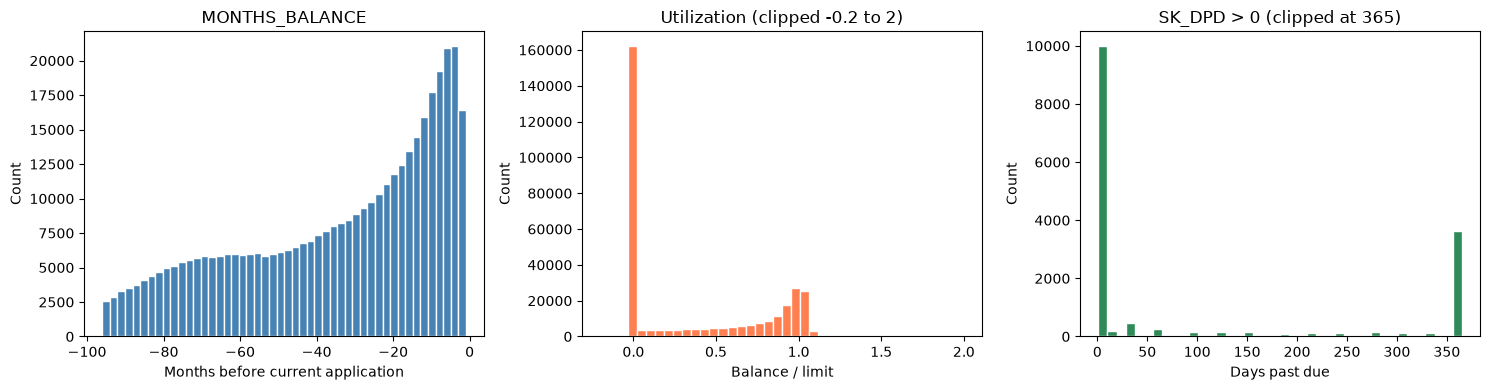

In [8]:
plot_sample = credit_card.sample(n=min(400_000, len(credit_card)), random_state=42)
util_sample = plot_sample.loc[plot_sample["AMT_CREDIT_LIMIT_ACTUAL"] > 0].copy()
util_sample["utilization"] = util_sample["AMT_BALANCE"] / util_sample["AMT_CREDIT_LIMIT_ACTUAL"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(plot_sample["MONTHS_BALANCE"], bins=48, color="steelblue", edgecolor="white")
axes[0].set_title("MONTHS_BALANCE")
axes[0].set_xlabel("Months before current application")
axes[0].set_ylabel("Count")

axes[1].hist(
    util_sample["utilization"].clip(-0.2, 2.0),
    bins=40,
    color="coral",
    edgecolor="white",
)
axes[1].set_title("Utilization (clipped -0.2 to 2)")
axes[1].set_xlabel("Balance / limit")
axes[1].set_ylabel("Count")

axes[2].hist(
    plot_sample.loc[plot_sample["SK_DPD"] > 0, "SK_DPD"].clip(upper=365),
    bins=40,
    color="seagreen",
    edgecolor="white",
)
axes[2].set_title("SK_DPD > 0 (clipped at 365)")
axes[2].set_xlabel("Days past due")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()


## 8. FE / join / leakage notes

Preview client-level aggregates and document join paths. Credit-card history is sparse at the client level, so availability indicators matter as much as the aggregates themselves.


In [9]:
cc_fe = credit_card.copy()
cc_fe["is_dpd"] = cc_fe["SK_DPD"] > 0
cc_fe["is_active"] = cc_fe["NAME_CONTRACT_STATUS"].eq("Active")
cc_fe["utilization"] = np.where(
    cc_fe["AMT_CREDIT_LIMIT_ACTUAL"] > 0,
    cc_fe["AMT_BALANCE"] / cc_fe["AMT_CREDIT_LIMIT_ACTUAL"],
    np.nan,
)
cc_fe["payment_lt_min"] = (
    cc_fe["AMT_PAYMENT_CURRENT"] < cc_fe["AMT_INST_MIN_REGULARITY"]
)

prev_fe = (
    cc_fe.groupby(["SK_ID_CURR", "SK_ID_PREV"], as_index=False)
    .agg(
        months=("MONTHS_BALANCE", "size"),
        mean_balance=("AMT_BALANCE", "mean"),
        mean_utilization=("utilization", "mean"),
        max_utilization=("utilization", "max"),
        max_dpd=("SK_DPD", "max"),
        dpd_month_rate=("is_dpd", "mean"),
        mean_drawings=("AMT_DRAWINGS_CURRENT", "mean"),
        payment_lt_min_rate=("payment_lt_min", "mean"),
    )
)

client_fe_preview = (
    prev_fe.groupby("SK_ID_CURR", as_index=False)
    .agg(
        cc_previous_apps=("SK_ID_PREV", "nunique"),
        cc_months=("months", "sum"),
        mean_max_utilization=("max_utilization", "mean"),
        mean_max_dpd=("max_dpd", "mean"),
        any_dpd=("max_dpd", lambda s: int((s > 0).any())),
        mean_dpd_month_rate=("dpd_month_rate", "mean"),
    )
)

display(Markdown("**Example client-level credit-card aggregates (preview only)**"))
display(client_fe_preview.head(5).style.hide(axis="index"))


**Example client-level credit-card aggregates (preview only)**

SK_ID_CURR,cc_previous_apps,cc_months,mean_max_utilization,mean_max_dpd,any_dpd,mean_dpd_month_rate
100006,1,6,0.000000,0.000000,0,0.000000
100011,1,74,1.050000,0.000000,0,0.000000
100013,1,96,1.024890,1.000000,1,0.010417
100021,1,17,0.000000,0.000000,0,0.000000
100023,1,8,0.000000,0.000000,0,0.000000


**Join path for FE:** aggregate monthly rows to `SK_ID_PREV`, then to `SK_ID_CURR`. Use `SK_ID_PREV` to link with `previous_application` (especially revolving loans) and installment history.

**Leakage caution:** `MONTHS_BALANCE`, balances, payments, and DPD are relative to the current application and describe previous-card history, which is appropriate. Rare statuses such as `Demand` are informative but target-like and should be handled carefully.

**Fairness / proxy note:** this table has no protected attributes. Utilization, drawing intensity, and delinquency may still correlate with socioeconomic factors and should be available for later audit in `07_protected_attributes.ipynb`.


## Summary of findings

_Executed successfully on 2026-07-17._

- **Grain / keys:** `credit_card_balance` has 3,840,312 rows x 23 columns (~888 MB). IDs have no nulls, there are no exact duplicates, and monthly grain is unique on (`SK_ID_PREV`, `MONTHS_BALANCE`).
- **Missingness:** No column exceeds 50% missing. Drawing-detail fields and `AMT_PAYMENT_CURRENT` are missing for ~20% of months (as a block). `AMT_INST_MIN_REGULARITY` and `CNT_INSTALMENT_MATURE_CUM` are missing together (~8%).
- **Coverage:** Credit-card history covers only ~28.3% of train clients and ~34.2% of test clients - much sparser than POS/installments/bureau. Clients with card history have a slightly higher raw train default rate (~8.7% vs ~7.8%); descriptive only. About 72% of credit-card `SK_ID_PREV` values join to `previous_application`; only ~5.6% of all previous applications have card rows, but ~48% of revolving previous applications do.
- **History:** `MONTHS_BALANCE` ranges from -96 to -1. Cards with history have a median of ~21 monthly snapshots (mean ~37, max 96).
- **Status / amounts:** Months are mostly `Active` (~96.3%). About 56% of months have zero balance; ~20% have zero credit limit. Utilization (when limit > 0) has median near 0 but a long upper tail, with ~11% of those months over limit (`utilization > 1`).
- **Payments / drawings:** Drawing activity occurs in ~16% of months. Payments below the minimum due are uncommon (~4% of comparable rows) but useful after aggregation. Receivable fields are nearly redundant (`AMT_RECIVABLE` ~ `AMT_TOTAL_RECEIVABLE`).
- **DPD:** `SK_DPD > 0` on ~4.0% of months; `SK_DPD_DEF > 0` on ~2.3%. `Demand` concentrates delinquency. Negative balances/receivables exist and should be clipped or flagged in FE.
- **FE implications:** Aggregate months to `SK_ID_PREV` then `SK_ID_CURR`. Prioritize a missing-card-history indicator, then utilization, max/mean DPD, drawing intensity, payment-below-minimum rate, and history length. Keep one receivable field, not all three.
- **Leakage / fairness notes:** Month, balance, payment, and DPD fields are application-relative historical signals. Rare statuses such as `Demand` are informative but should be handled carefully. No protected attributes here; utilization and delinquency may still correlate with socioeconomic factors for later audit.
